         year    eps  delta                  method  hospitals  loss_harm  cal_harm  either  point_above  nonlocal_  mean_loss_diff  auroc_gain
0   2022 test  0.005  0.010                  Pooled        126        0.6       4.8     5.2         68.8        NaN          0.0029      0.0005
1   2022 test  0.005  0.010             Fine-tuning        126        0.0       0.0     0.0          6.8        NaN         -0.0004      0.0035
2   2022 test  0.005  0.010       Pooled, certified        126        0.0       0.0     0.0          0.0       17.0          0.0000      0.0002
3   2022 test  0.005  0.010  Fine-tuning, certified        126        0.0       0.0     0.0          0.0       17.4          0.0000     -0.0000
4   2022 test  0.010  0.015                  Pooled        126        0.4       2.0     2.4         48.8        NaN          0.0029      0.0005
5   2022 test  0.010  0.015             Fine-tuning        126        0.0       0.0     0.0          1.8        NaN         -0.0004     

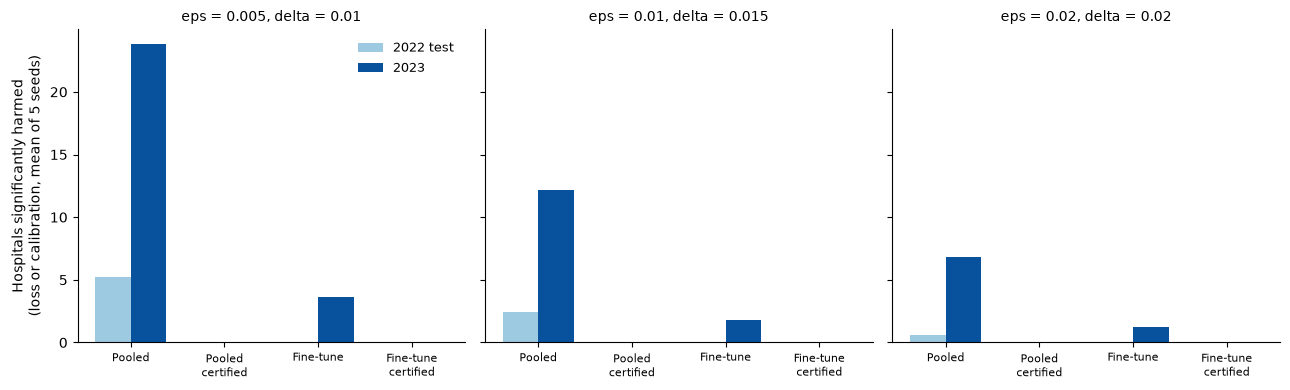

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy import stats
from statsmodels.stats.multitest import multipletests
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]
A = {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv").copy() for s in seeds}
Tm = {s: pd.read_csv(f"../outputs/tables/temporal_2023_seed{s}.csv").copy() for s in seeds}
HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]

def loss_mask(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

def row(r, pre, eps, delta):
    lm = loss_mask(r, pre, eps); cm = r[f"{pre}__gaplb"].values > delta
    return dict(loss_harm=lm.sum(), cal_harm=cm.sum(), either=(lm | cm).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean())

rows = []
for year, D in (("2022 test", A), ("2023", Tm)):
    for eps, delta in HEAD:
        for label, pre in [("Pooled", "pool_full"), ("Fine-tuning", "ft_full"),
                           ("Pooled, certified", f"cert_pool_e{eps}_d{delta}"), ("Fine-tuning, certified", f"cert_ft_e{eps}_d{delta}")]:
            res = pd.DataFrame([row(D[s], pre, eps, delta) for s in seeds]).mean()
            rows.append({"year": year, "eps": eps, "delta": delta, "method": label, "hospitals": len(D[seeds[0]]), **res.to_dict()})
T17 = pd.DataFrame(rows)
T17.to_csv("../outputs/tables/T17_temporal.csv", index=False)
print(T17.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
meths = ["Pooled", "Pooled, certified", "Fine-tuning", "Fine-tuning, certified"]
for a, (eps, delta) in zip(ax, HEAD):
    for i, (yr, c) in enumerate([("2022 test", "#9ecae1"), ("2023", "#08519c")]):
        v = [T17[(T17.year == yr) & (T17.eps == eps) & (T17.method == m)].either.values[0] for m in meths]
        a.bar(np.arange(4) + (i - 0.5) * 0.38, v, 0.38, color=c, label=yr)
    a.set_xticks(range(4)); a.set_xticklabels(["Pooled", "Pooled\ncertified", "Fine-tune", "Fine-tune\ncertified"], fontsize=8)
    a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean of 5 seeds)"); ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("../outputs/figures/fig16_temporal.png", dpi=300); plt.savefig("../outputs/figures/fig16_temporal.pdf"); plt.show()

        version    eps  delta                  method  either  point_above  nonlocal_  mean_loss_diff  auroc_gain  local_auroc
0   without APR  0.005  0.010                  Pooled     5.2         68.8        NaN          0.0029      0.0005       0.8145
1   without APR  0.005  0.010             Fine-tuning     0.0          6.8        NaN         -0.0004      0.0035       0.8145
2   without APR  0.005  0.010       Pooled, certified     0.0          0.0       17.0          0.0000      0.0002       0.8145
3   without APR  0.005  0.010  Fine-tuning, certified     0.0          0.0       17.4          0.0000     -0.0000       0.8145
4   without APR  0.010  0.015                  Pooled     2.4         48.8        NaN          0.0029      0.0005       0.8145
5   without APR  0.010  0.015             Fine-tuning     0.0          1.8        NaN         -0.0004      0.0035       0.8145
6   without APR  0.010  0.015       Pooled, certified     0.0          0.0       55.8          0.0001      0.00

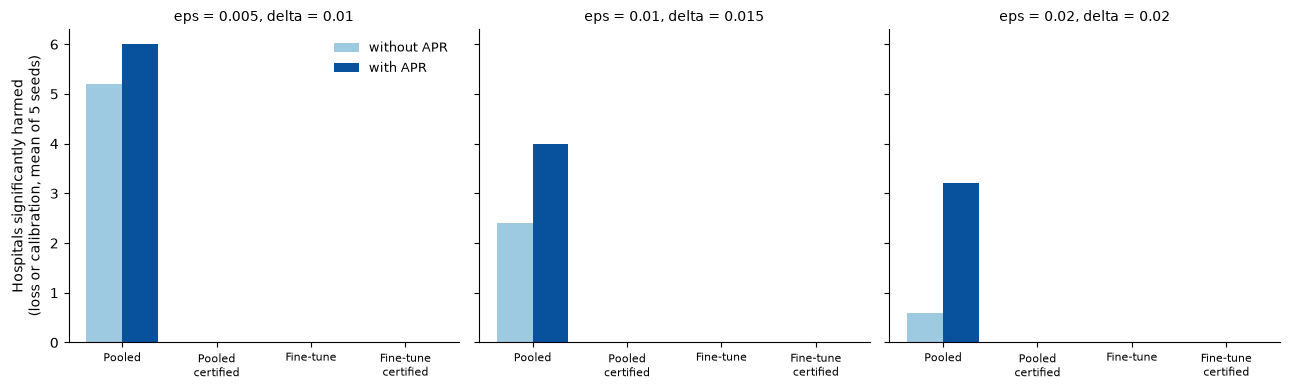

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
V = {"without APR": {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv").copy() for s in seeds},
     "with APR": {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}_apr.csv").copy() for s in seeds}}

def lm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for ver, D in V.items():
    for eps, delta in HEAD:
        for label, pre in [("Pooled", "pool_full"), ("Fine-tuning", "ft_full"),
                           ("Pooled, certified", f"cert_pool_e{eps}_d{delta}"), ("Fine-tuning, certified", f"cert_ft_e{eps}_d{delta}")]:
            out = []
            for s in seeds:
                r = D[s]; l = lm(r, pre, eps); c = r[f"{pre}__gaplb"].values > delta
                out.append(dict(either=(l | c).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                                mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean(),
                                local_auroc=r["local__auroc"].mean()))
            rows.append({"version": ver, "eps": eps, "delta": delta, "method": label, **pd.DataFrame(out).mean().to_dict()})
T19 = pd.DataFrame(rows); T19.to_csv("../outputs/tables/T19_apr_sensitivity.csv", index=False)
print(T19.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
meths = ["Pooled", "Pooled, certified", "Fine-tuning", "Fine-tuning, certified"]
for a, (eps, delta) in zip(ax, HEAD):
    for i, (ver, c) in enumerate([("without APR", "#9ecae1"), ("with APR", "#08519c")]):
        v = [T19[(T19.version == ver) & (T19.eps == eps) & (T19.method == m)].either.values[0] for m in meths]
        a.bar(np.arange(4) + (i - 0.5) * 0.38, v, 0.38, color=c, label=ver)
    a.set_xticks(range(4)); a.set_xticklabels(["Pooled", "Pooled\ncertified", "Fine-tune", "Fine-tune\ncertified"], fontsize=8)
    a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean of 5 seeds)"); ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("../outputs/figures/fig20_apr_sensitivity.png", dpi=300); plt.savefig("../outputs/figures/fig20_apr_sensitivity.pdf"); plt.show()